# Case Study: Credit Risk Analysis with CART (German Credit Dataset)
**Name:** Muhammad Naafir A  |  **Course:** Modules III & IV  |  **Tool:** Python (Google Colab)

**Dataset:** Statlog German Credit Data (UCI / OpenML `credit-g`), 1000 loan applicants, 20 attributes.
**Classification goal:** predict credit risk (good / bad). **Regression goal:** predict the loan amount.

## Step 1: Retrieve and import the dataset

In [55]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_curve,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.utils import resample
sns.set_style('whitegrid')

# Dataset is downloaded once, then FROZEN as a CSV so the presentation always uses the same data
FROZEN = 'credit_g_frozen.csv'
if os.path.exists(FROZEN):
    df = pd.read_csv(FROZEN)
else:
    raw = fetch_openml('credit-g', version=1, as_frame=True)
    df = raw.frame.copy()
    df.to_csv(FROZEN, index=False)

print(df.shape)
df.head()

(1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [56]:
df.info()
print('Missing values:', df.isna().sum().sum(), '| Duplicate rows:', df.duplicated().sum())
print(df['class'].value_counts())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   checking_status         1000 non-null   object
 1   duration                1000 non-null   int64 
 2   credit_history          1000 non-null   object
 3   purpose                 1000 non-null   object
 4   credit_amount           1000 non-null   int64 
 5   savings_status          1000 non-null   object
 6   employment              1000 non-null   object
 7   installment_commitment  1000 non-null   int64 
 8   personal_status         1000 non-null   object
 9   other_parties           1000 non-null   object
 10  residence_since         1000 non-null   int64 
 11  property_magnitude      1000 non-null   object
 12  age                     1000 non-null   int64 
 13  other_payment_plans     1000 non-null   object
 14  housing                 1000 non-null   object
 15  exist

,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,num_dependents
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000


## Step 2: Data preparation (index field + changing field values)

In [57]:
# (a) Add an index (record ID) field
df.insert(0, 'ID', np.arange(1, len(df) + 1))

# (b) Change field values: target text -> numeric (good=0, bad=1)
df['Risk'] = df['class'].astype(str).map({'good': 0, 'bad': 1}).astype(int)
df.drop(columns='class', inplace=True)

# (c) Change other field values: yes/no -> 1/0
df['foreign_worker'] = df['foreign_worker'].astype(str).map({'yes': 1, 'no': 0}).astype(int)

# (d) Make a readable text label for purpose, e.g. 'new car' -> 'New Car'
df['purpose'] = df['purpose'].str.title()
df.head()

,ID,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,Risk
0,1,<0,6,critical/other existing credit,Radio/Tv,1169,no known savings,>=7,4,male single,...,real estate,67,none,own,2,skilled,1,yes,1,0
1,2,0<=X<200,48,existing paid,Radio/Tv,5951,<100,1<=X<4,2,female div/dep/mar,...,real estate,22,none,own,1,skilled,1,none,1,1
2,3,no checking,12,critical/other existing credit,Education,2096,<100,4<=X<7,2,male single,...,real estate,49,none,own,1,unskilled resident,2,none,1,0
3,4,<0,42,existing paid,Furniture/Equipment,7882,<100,4<=X<7,2,male single,...,life insurance,45,none,for free,1,skilled,2,none,1,0
4,5,<0,24,delayed previously,New Car,4870,<100,1<=X<4,3,male single,...,no known property,53,none,for free,2,skilled,2,none,1,1


## Step 3: Identify and handle categorical data

In [58]:
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = [c for c in df.select_dtypes(include='number').columns if c not in ('ID', 'Risk')]
print('Categorical fields:', cat_cols)
print('Numeric fields    :', num_cols)
for c in cat_cols:
    print(f'{c}: {df[c].nunique()} levels ->', df[c].unique().tolist())

Categorical fields: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone']
Numeric fields    : ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents', 'foreign_worker']
checking_status: 4 levels -> ['<0', '0<=X<200', 'no checking', '>=200']
credit_history: 5 levels -> ['critical/other existing credit', 'existing paid', 'delayed previously', 'no credits/all paid', 'all paid']
purpose: 10 levels -> ['Radio/Tv', 'Education', 'Furniture/Equipment', 'New Car', 'Used Car', 'Business', 'Domestic Appliance', 'Repairs', 'Other', 'Retraining']
savings_status: 5 levels -> ['no known savings', '<100', '500<=X<1000', '>=1000', '100<=X<500']
employment: 5 levels -> ['>=7', '1<=X<4', '4<=X<7', 'unemployed', '<1']
personal_status: 4 levels -> ['male single', 'female div/dep/mar', 'male div/sep', 'ma

In [59]:
# One-hot (dummy) encoding of nominal categorical fields; drop_first avoids redundant columns
df_enc = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
dummy_cols = [c for c in df_enc.columns if c not in df.columns]
print('Shape before:', df.shape, '| after encoding:', df_enc.shape)
print('New dummy fields:', len(dummy_cols))

Shape before: (1000, 22) | after encoding: (1000, 50)
New dummy fields: 40


## Step 4: Re-expression techniques (fixing skewness)

Skewness BEFORE:
 duration         1.094
credit_amount    1.950
age              1.021
dtype: float64

Skewness AFTER (log):
 duration_log        -0.051
credit_amount_log    0.130
age_log              0.432
dtype: float64


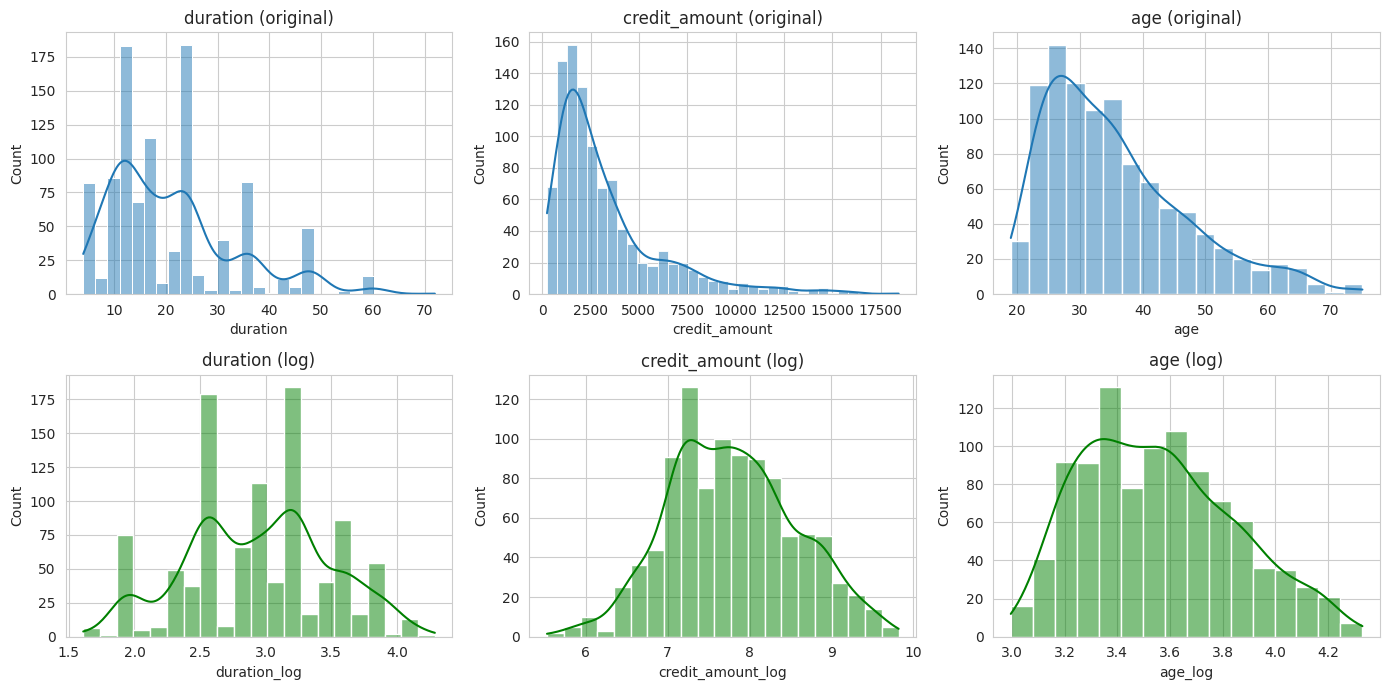

In [60]:
skew_cols = ['duration', 'credit_amount', 'age']
print('Skewness BEFORE:\n', df_enc[skew_cols].skew().round(3))
for c in skew_cols:
    df_enc[c + '_log'] = np.log1p(df_enc[c])        # log re-expression
print('\nSkewness AFTER (log):\n', df_enc[[c + '_log' for c in skew_cols]].skew().round(3))

fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for i, c in enumerate(skew_cols):
    sns.histplot(df_enc[c], kde=True, ax=ax[0, i]).set_title(f'{c} (original)')
    sns.histplot(df_enc[c + '_log'], kde=True, ax=ax[1, i], color='green').set_title(f'{c} (log)')
plt.tight_layout(); plt.show()

## Step 5: Standardize numerical data (z-score)

In [61]:
num_model = ['duration_log', 'credit_amount_log', 'age_log',
             'installment_commitment', 'residence_since', 'existing_credits', 'num_dependents']
scaler = StandardScaler()
z_cols = [c + '_z' for c in num_model]
df_enc[z_cols] = scaler.fit_transform(df_enc[num_model])
print(df_enc[z_cols].agg(['mean', 'std']).round(3))   # mean ~ 0, std ~ 1

      duration_log_z  credit_amount_log_z  age_log_z  \
mean           0.000                0.000      0.000   
std            1.001                1.001      1.001   

      installment_commitment_z  residence_since_z  existing_credits_z  \
mean                     0.000             -0.000              -0.000   
std                      1.001              1.001               1.001   

      num_dependents_z  
mean            -0.000  
std              1.001  


## Step 6: Identify and handle outliers

Outliers by |z|>3 rule:
 duration_log_z              0
credit_amount_log_z         0
age_log_z                   0
installment_commitment_z    0
residence_since_z           0
existing_credits_z          6
num_dependents_z            0
dtype: int64


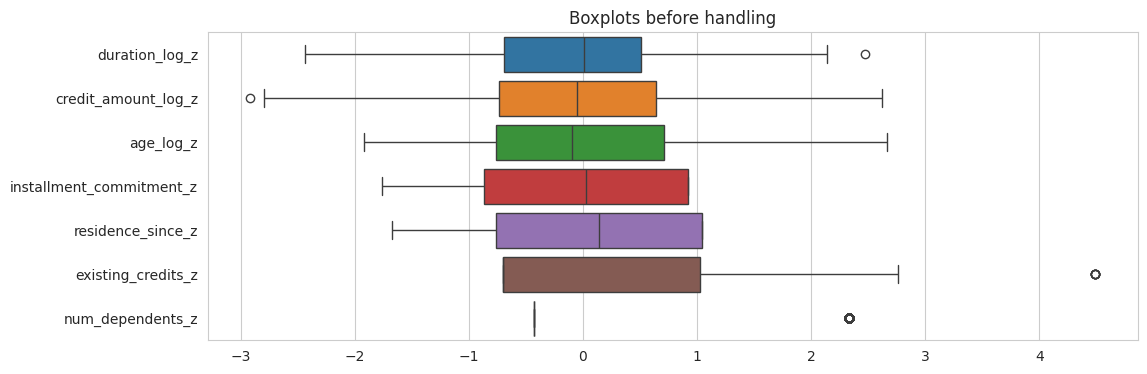


Outliers after capping: 0


In [62]:
# Identify: |z| > 3 rule and IQR (boxplot) rule
out_z = (df_enc[z_cols].abs() > 3).sum()
print('Outliers by |z|>3 rule:\n', out_z)
plt.figure(figsize=(12, 4)); sns.boxplot(data=df_enc[z_cols], orient='h'); plt.title('Boxplots before handling'); plt.show()

# Handle: winsorize (cap) standardized values at +/- 3 instead of deleting records
df_enc[z_cols] = df_enc[z_cols].clip(-3, 3)
print('\nOutliers after capping:', int((df_enc[z_cols].abs() > 3).sum().sum()))

## Step 7: Partition into training and testing sets (70 / 30, stratified)

In [63]:
feature_cols = z_cols + dummy_cols + ['foreign_worker']
feature_cols = list(dict.fromkeys(feature_cols))      # remove duplicates, keep order
X = df_enc[feature_cols]
y = df_enc['Risk']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (700, 48) | Test: (300, 48)


## Step 8: Validate the partition and balance the training data

In [64]:
# (a) Class proportions should be similar in both sets
print('Train Risk %:\n', y_train.value_counts(normalize=True).round(3))
print('Test Risk %:\n', y_test.value_counts(normalize=True).round(3))

# (b) Chi-square test on the target proportion (p > 0.05 => partitions are statistically similar)
ct = pd.crosstab(np.r_[np.zeros(len(y_train)), np.ones(len(y_test))], np.r_[y_train, y_test])
print('Chi-square p-value (Risk):', round(stats.chi2_contingency(ct)[1], 4))

# (c) Two-sample t-test on numeric fields
rows = []
for c in z_cols:
    t, p = stats.ttest_ind(X_train[c], X_test[c], equal_var=False)
    rows.append((c, round(X_train[c].mean(), 3), round(X_test[c].mean(), 3), round(p, 3)))
print(pd.DataFrame(rows, columns=['field', 'train_mean', 'test_mean', 'p_value']))

Train Risk %:
 Risk
0    0.7
1    0.3
Name: proportion, dtype: float64
Test Risk %:
 Risk
0    0.7
1    0.3
Name: proportion, dtype: float64
Chi-square p-value (Risk): 1.0
                      field  train_mean  test_mean  p_value
0            duration_log_z      -0.012      0.028    0.555
1       credit_amount_log_z      -0.017      0.041    0.406
2                 age_log_z       0.003     -0.006    0.898
3  installment_commitment_z      -0.031      0.072    0.135
4         residence_since_z      -0.023      0.053    0.278
5        existing_credits_z      -0.014      0.002    0.824
6          num_dependents_z       0.010     -0.023    0.630


In [65]:
# (d) Balance the TRAINING set only (random oversampling of the minority class 'bad')
train = pd.concat([X_train, y_train], axis=1)
maj, mino = train[train.Risk == 0], train[train.Risk == 1]
mino_up = resample(mino, replace=True, n_samples=len(maj), random_state=42)
train_bal = pd.concat([maj, mino_up]).sample(frac=1, random_state=42)
X_train_bal, y_train_bal = train_bal.drop(columns='Risk'), train_bal['Risk']
print('Before balancing:', y_train.value_counts().to_dict())
print('After balancing :', y_train_bal.value_counts().to_dict())

Before balancing: {0: 490, 1: 210}
After balancing : {1: 490, 0: 490}


## Step 9: Build the CART classification model

Best parameters: {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 10}


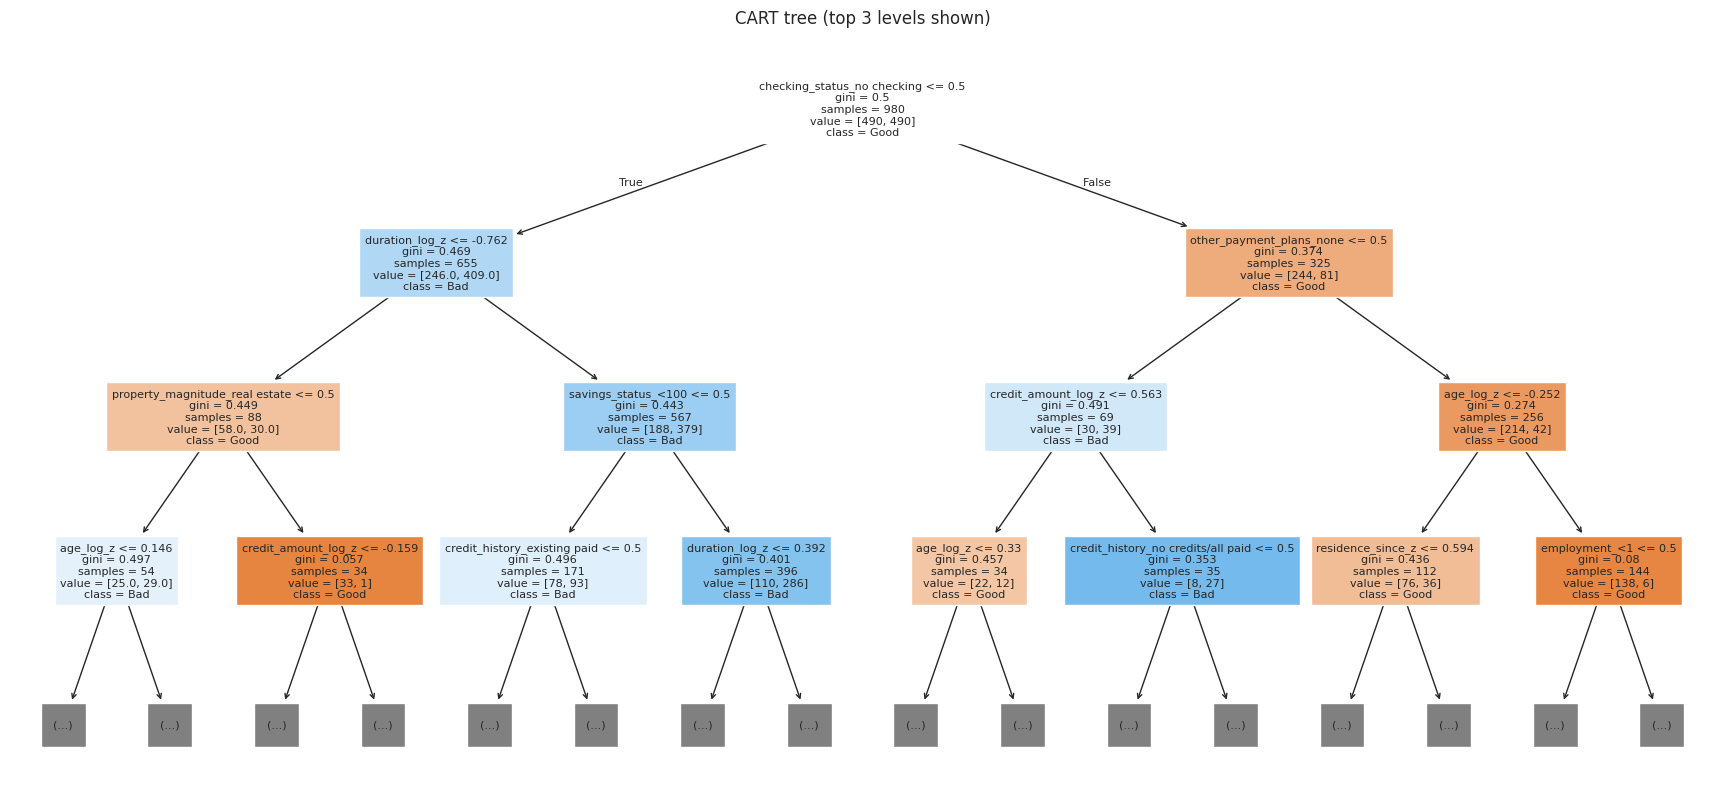

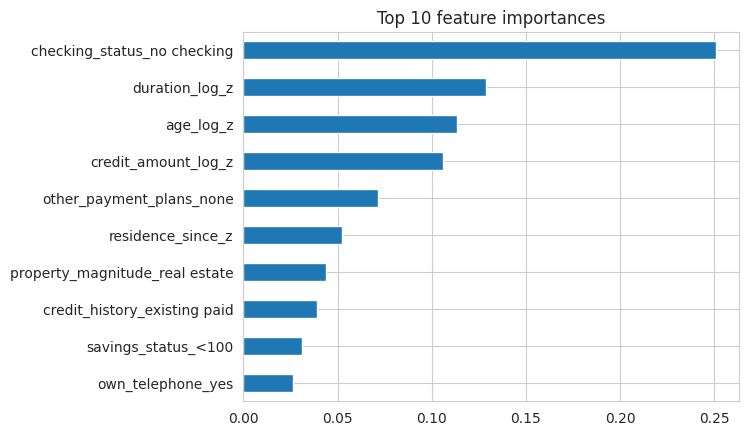

In [66]:
params = {'max_depth': [3, 4, 5, 6, 8], 'min_samples_leaf': [5, 10, 20], 'criterion': ['gini', 'entropy']}
gs = GridSearchCV(DecisionTreeClassifier(random_state=42), params, cv=5, scoring='f1', n_jobs=-1)
gs.fit(X_train_bal, y_train_bal)
cart = gs.best_estimator_
print('Best parameters:', gs.best_params_)

plt.figure(figsize=(22, 10))
plot_tree(cart, feature_names=X.columns, class_names=['Good', 'Bad'], filled=True, max_depth=3, fontsize=8)
plt.title('CART tree (top 3 levels shown)'); plt.show()

imp = pd.Series(cart.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind='barh', title='Top 10 feature importances'); plt.show()

## Step 10: Evaluate the model

              precision    recall  f1-score   support

        Good       0.79      0.69      0.74       210
         Bad       0.44      0.57      0.50        90

    accuracy                           0.65       300
   macro avg       0.61      0.63      0.62       300
weighted avg       0.68      0.65      0.66       300

Accuracy : 0.653
Precision: 0.44
Recall   : 0.567
F1-score : 0.495
ROC-AUC  : 0.679


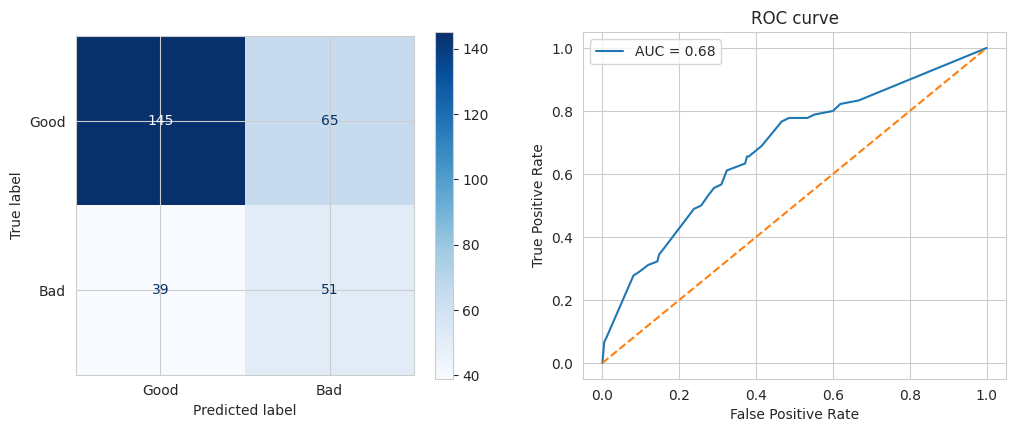

Unbalanced-train recall for Bad: 0.467 | Balanced-train recall: 0.567


In [67]:
pred = cart.predict(X_test)
prob = cart.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred, target_names=['Good', 'Bad']))
print('Accuracy :', round(accuracy_score(y_test, pred), 3))
print('Precision:', round(precision_score(y_test, pred), 3))
print('Recall   :', round(recall_score(y_test, pred), 3))
print('F1-score :', round(f1_score(y_test, pred), 3))
print('ROC-AUC  :', round(roc_auc_score(y_test, prob), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Good', 'Bad']).plot(ax=ax[0], cmap='Blues')
fpr, tpr, _ = roc_curve(y_test, prob)
ax[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, prob):.2f}'); ax[1].plot([0, 1], [0, 1], '--')
ax[1].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC curve'); ax[1].legend()
plt.show()

# Compare with a tree trained WITHOUT balancing (shows the effect of Step 8)
cart_unbal = DecisionTreeClassifier(**{k: v for k, v in gs.best_params_.items()}, random_state=42).fit(X_train, y_train)
print('Unbalanced-train recall for Bad:', round(recall_score(y_test, cart_unbal.predict(X_test)), 3),
      '| Balanced-train recall:', round(recall_score(y_test, pred), 3))

### Regression tree (CART for a numeric target): predict loan amount

Best parameters: {'max_depth': 5, 'min_samples_leaf': 10}
R2   : 0.511
MAE  (log scale): 0.417
RMSE (log scale): 0.552
MAE  in original currency units (DM): 1390.1


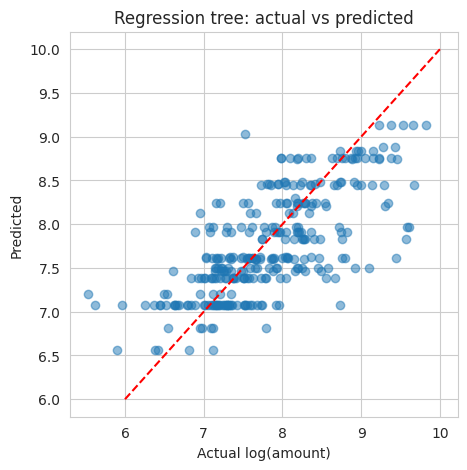

In [68]:
# Target = log(credit_amount); exclude the amount itself from the predictors to avoid leakage
reg_features = [c for c in X.columns if c != 'credit_amount_log_z']
y_reg = df_enc['credit_amount_log']
Xr_train, Xr_test = X_train[reg_features], X_test[reg_features]
yr_train, yr_test = y_reg.loc[X_train.index], y_reg.loc[X_test.index]

gs_r = GridSearchCV(DecisionTreeRegressor(random_state=42),
                    {'max_depth': [3, 4, 5, 6, 8], 'min_samples_leaf': [5, 10, 20, 30]},
                    cv=5, scoring='neg_mean_squared_error', n_jobs=-1).fit(Xr_train, yr_train)
reg = gs_r.best_estimator_
pr = reg.predict(Xr_test)
print('Best parameters:', gs_r.best_params_)
print('R2   :', round(r2_score(yr_test, pr), 3))
print('MAE  (log scale):', round(mean_absolute_error(yr_test, pr), 3))
print('RMSE (log scale):', round(np.sqrt(mean_squared_error(yr_test, pr)), 3))
print('MAE  in original currency units (DM):', round(mean_absolute_error(np.expm1(yr_test), np.expm1(pr)), 1))

plt.figure(figsize=(5, 5)); plt.scatter(yr_test, pr, alpha=.5); plt.plot([6, 10], [6, 10], 'r--')
plt.xlabel('Actual log(amount)'); plt.ylabel('Predicted'); plt.title('Regression tree: actual vs predicted'); plt.show()

## Conclusion
Fill in with your own results: best CART parameters, top predictors (e.g. checking status, duration, credit history),
accuracy / recall / F1 / AUC, how balancing changed recall for the *Bad* class, and R2 / MAE of the regression tree.
Mention limitations (small dataset, oversampling duplicates records, single train/test split) and future work (pruning, Random Forest).

In [69]:
print("STEP 4 - Skewness BEFORE:\n", df_enc[['duration','credit_amount','age']].skew().round(3))
print("\nSTEP 4 - Skewness AFTER (log):\n", df_enc[['duration_log','credit_amount_log','age_log']].skew().round(3))

print("\nSTEP 6 - Outliers found (|z|>3, before capping):\n", out_z)

print("\nSTEP 9 - Best parameters:", gs.best_params_)

print("\nSTEP 10 - Classification metrics")
print("Accuracy :", round(accuracy_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall   :", round(recall_score(y_test, pred), 3))
print("F1-score :", round(f1_score(y_test, pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, prob), 3))
print("Recall (Bad) WITHOUT balancing:", round(recall_score(y_test, cart_unbal.predict(X_test)), 3))
print("Recall (Bad) WITH balancing   :", round(recall_score(y_test, pred), 3))
print("Confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, pred))

print("\nREGRESSION - Best parameters:", gs_r.best_params_)
print("R2   :", round(r2_score(yr_test, pr), 3))
print("MAE  (log scale):", round(mean_absolute_error(yr_test, pr), 3))
print("RMSE (log scale):", round(np.sqrt(mean_squared_error(yr_test, pr)), 3))

STEP 4 - Skewness BEFORE:
 duration         1.094
credit_amount    1.950
age              1.021
dtype: float64

STEP 4 - Skewness AFTER (log):
 duration_log        -0.051
credit_amount_log    0.130
age_log              0.432
dtype: float64

STEP 6 - Outliers found (|z|>3, before capping):
 duration_log_z              0
credit_amount_log_z         0
age_log_z                   0
installment_commitment_z    0
residence_since_z           0
existing_credits_z          6
num_dependents_z            0
dtype: int64

STEP 9 - Best parameters: {'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 10}

STEP 10 - Classification metrics
Accuracy : 0.653
Precision: 0.44
Recall   : 0.567
F1-score : 0.495
ROC-AUC  : 0.679
Recall (Bad) WITHOUT balancing: 0.467
Recall (Bad) WITH balancing   : 0.567
Confusion matrix [[TN FP] [FN TP]]:
 [[145  65]
 [ 39  51]]

REGRESSION - Best parameters: {'max_depth': 5, 'min_samples_leaf': 10}
R2   : 0.511
MAE  (log scale): 0.417
RMSE (log scale): 0.552


In [70]:
import os, shutil
os.makedirs('figs', exist_ok=True)

# Fig 1: skewness before/after log
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for i, c in enumerate(['duration', 'credit_amount', 'age']):
    sns.histplot(df_enc[c], kde=True, ax=ax[0, i]).set_title(f'{c} (original)')
    sns.histplot(df_enc[c + '_log'], kde=True, ax=ax[1, i], color='green').set_title(f'{c} (log)')
plt.tight_layout(); plt.savefig('figs/fig1_skewness.png', dpi=150); plt.close()

# Fig 2: outliers before/after capping
z_before = pd.DataFrame(StandardScaler().fit_transform(df_enc[num_model]), columns=z_cols)
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
sns.boxplot(data=z_before, orient='h', ax=ax[0]).set_title('Before capping')
sns.boxplot(data=df_enc[z_cols], orient='h', ax=ax[1]).set_title('After capping at +/-3')
plt.tight_layout(); plt.savefig('figs/fig2_outliers.png', dpi=150); plt.close()

# Fig 3: class balance before/after
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
y_train.value_counts().sort_index().plot(kind='bar', ax=ax[0], title='Train (before balancing)')
y_train_bal.value_counts().sort_index().plot(kind='bar', ax=ax[1], title='Train (after balancing)', color='green')
plt.tight_layout(); plt.savefig('figs/fig3_balance.png', dpi=150); plt.close()

# Fig 4: CART tree (top 3 levels)
plt.figure(figsize=(22, 10))
plot_tree(cart, feature_names=X.columns, class_names=['Good', 'Bad'], filled=True, max_depth=3, fontsize=8)
plt.savefig('figs/fig4_tree.png', dpi=120); plt.close()

# Fig 5: feature importances
imp_all = pd.Series(cart.feature_importances_, index=X.columns).sort_values(ascending=False)
imp_all.head(10).sort_values().plot(kind='barh', title='Top 10 feature importances', figsize=(8, 5))
plt.tight_layout(); plt.savefig('figs/fig5_importance.png', dpi=150); plt.close()

# Fig 6: confusion matrix + ROC
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Good', 'Bad']).plot(ax=ax[0], cmap='Blues')
fpr, tpr, _ = roc_curve(y_test, prob)
ax[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, prob):.2f}'); ax[1].plot([0, 1], [0, 1], '--')
ax[1].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC curve'); ax[1].legend()
plt.tight_layout(); plt.savefig('figs/fig6_eval.png', dpi=150); plt.close()

# Fig 7: regression actual vs predicted
plt.figure(figsize=(5, 5)); plt.scatter(yr_test, pr, alpha=.5)
lo, hi = yr_test.min(), yr_test.max(); plt.plot([lo, hi], [lo, hi], 'r--')
plt.xlabel('Actual log(amount)'); plt.ylabel('Predicted'); plt.title('Regression tree: actual vs predicted')
plt.tight_layout(); plt.savefig('figs/fig7_regression.png', dpi=150); plt.close()

print('TOP 10 FEATURES:\n', imp_all.head(10).round(3))
print('Regression MAE in DM:', round(mean_absolute_error(np.expm1(yr_test), np.expm1(pr)), 1))
print('Accuracy WITHOUT balancing:', round(accuracy_score(y_test, cart_unbal.predict(X_test)), 3))

shutil.make_archive('figs', 'zip', 'figs')
from google.colab import files; files.download('figs.zip')

TOP 10 FEATURES:
 checking_status_no checking       0.251
duration_log_z                    0.129
age_log_z                         0.113
credit_amount_log_z               0.106
other_payment_plans_none          0.072
residence_since_z                 0.052
property_magnitude_real estate    0.044
credit_history_existing paid      0.039
savings_status_<100               0.031
own_telephone_yes                 0.026
dtype: float64
Regression MAE in DM: 1390.1
Accuracy WITHOUT balancing: 0.66


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>